# Práctica 2 · Alineamientos de secuencias con Biopython
**Asignatura:** Bioinformática · Grado en Ciencia e Ingeniería de Datos (ULPGC)  
**Integrantes:** Lucía Xufang Cruz Toste y Carlota Ayala Pérez

**Objetivo.** Aplicar `PairwiseAligner` a la exploración de penalizaciones de huecos, la comparación de secuencias de proteínas y el estudio del coste computacional. Se emplean las técnicas explicadas en la sesión 03: alineamiento global, función de puntuación, matrices de sustitución y programación dinámica.

> **Nota sobre los datos del ejercicio 2:** el material no incluye las cinco secuencias FASTA. Para dejar la práctica ejecutable sin conexiones externas se incorpora un FASTA **sintético y reproducible** con cinco variantes de una secuencia proteica de ejemplo. Estas variantes **no son secuencias verificadas de especies reales**. Si se proporcionan cinco secuencias homólogas reales en un FASTA, basta con sustituir el archivo generado para repetir todo el análisis.

## Ejercicio 1 · Búsqueda en rejilla de penalizaciones de huecos

Se comparan dos secuencias de ADN: una original (`GCATGCATGCATGC`) y otra más corta (`GCATGCGC`). El alineamiento se configura como **global**, de modo que se consideran las dos secuencias completas. La puntuación premia las coincidencias (`+1`), deja las sustituciones en `0` y penaliza la apertura y extensión de huecos.

Para un tramo de hueco de longitud $L$, la penalización afín que usa Biopython es $g_{apertura}+(L-1)g_{extensión}$. Se explora una rejilla y se cuenta cuántos alineamientos alcanzan la puntuación óptima. Este número puede ser mayor que uno cuando existen **empates**, sin que ello implique que se han encontrado soluciones de distinta calidad.

In [1]:
import random
from io import StringIO
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices

pd.set_option("display.max_columns", 20)

seq_sana = "GCATGCATGCATGC"
seq_paciente = "GCATGCGC"

# Rejilla elegida dentro del intervalo pedido por el enunciado.
aperturas = np.arange(-1, -21, -1)
extensiones = np.round(np.arange(-0.1, -5.01, -0.1), 2)

alineador = Align.PairwiseAligner()
alineador.mode = "global"
alineador.match_score = 1
alineador.mismatch_score = 0

resultados = []
for apertura in aperturas:
    for extension in extensiones:
        alineador.open_gap_score = float(apertura)
        alineador.extend_gap_score = float(extension)
        alineamientos = alineador.align(seq_sana, seq_paciente)
        resultados.append({
            "open_gap": float(apertura),
            "extend_gap": float(extension),
            "n_optimos": len(alineamientos),
            "mejor_score": alineamientos.score
        })

df_grid = pd.DataFrame(resultados)
print(f"Combinaciones analizadas: {len(df_grid)}")
display(df_grid.head(10))
print("Distribución del número de soluciones óptimas:")
display(df_grid['n_optimos'].value_counts().sort_index().rename_axis('n_optimos').to_frame('combinaciones'))

Combinaciones analizadas: 1000


,open_gap,extend_gap,n_optimos,mejor_score
0,-1.0,-0.1,1,6.5
1,-1.0,-0.2,1,6.0
2,-1.0,-0.3,1,5.5
3,-1.0,-0.4,1,5.0
4,-1.0,-0.5,1,4.5
5,-1.0,-0.6,1,4.0
6,-1.0,-0.7,1,3.5
7,-1.0,-0.8,1,3.0
8,-1.0,-0.9,1,2.5
9,-1.0,-1.0,9,2.0


Distribución del número de soluciones óptimas:


,combinaciones
n_optimos,
1,895
5,60
8,36
9,5
111,4


### Representación del espacio de parámetros

El mapa de calor permite detectar zonas con un solo alineamiento óptimo y zonas con varios empates. La gráfica muestra el **número de óptimos**, no la puntuación de similitud.

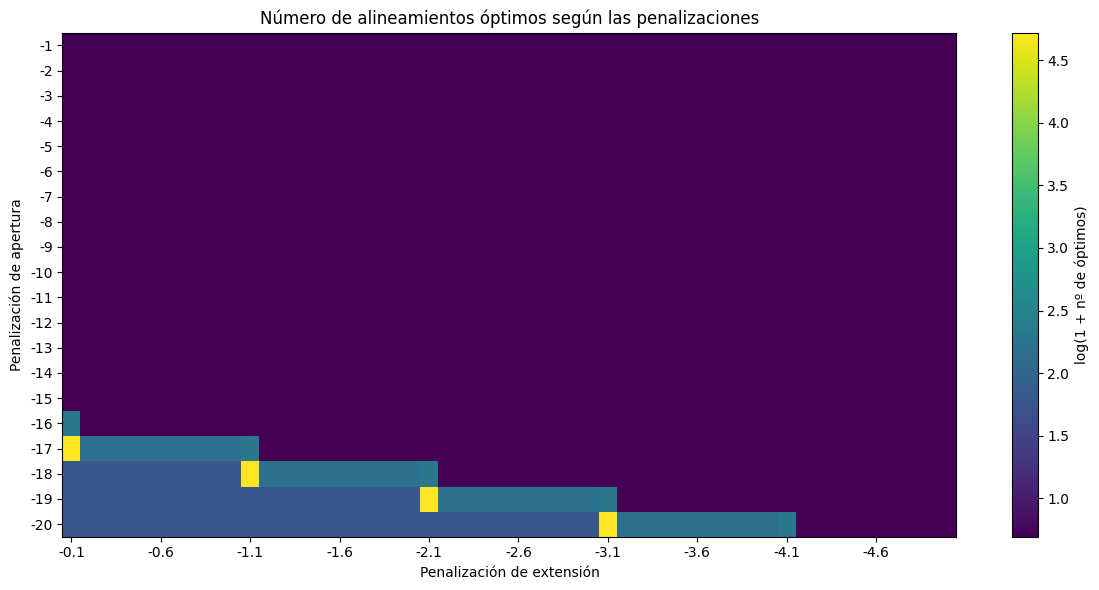

In [2]:
tabla_empates = df_grid.pivot(index="open_gap", columns="extend_gap", values="n_optimos")
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(np.log1p(tabla_empates.values), aspect="auto", origin="upper", cmap="viridis")
ax.set_xticks(np.arange(0, len(extensiones), 5), labels=[f"{x:.1f}" for x in extensiones[::5]])
ax.set_yticks(np.arange(len(aperturas)), labels=[f"{x:.0f}" for x in aperturas])
ax.set_xlabel("Penalización de extensión")
ax.set_ylabel("Penalización de apertura")
ax.set_title("Número de alineamientos óptimos según las penalizaciones")
fig.colorbar(im, ax=ax, label="log(1 + nº de óptimos)")
plt.tight_layout()
plt.show()

### Localización matemática de una transición exacta

El enunciado solicita el punto donde el algoritmo pasa de múltiples soluciones óptimas a una sola. **No existe necesariamente un punto único para todo un espacio bidimensional**: pueden darse varias fronteras y regiones de empate. Para identificar una transición demostrable fijamos `extend_gap = -1` y estudiamos el valor de apertura alrededor de `-1`.

Con estos datos y el esquema de puntuación elegido, compiten dos tipos de alineamiento:

- **Un hueco de seis posiciones**, que conserva 8 coincidencias: $S_A=8+o+5e$.
- **Dos huecos de cuatro y dos posiciones**, que conservan 8 coincidencias: $S_B=8+2o+4e$.

La igualdad entre ambas alternativas se produce cuando $8+o+5e=8+2o+4e$, es decir, **$o=e$**. Por tanto, para la sección estudiada `e = -1`, la frontera está en **`open_gap = -1`**. En la propia frontera hay empates; al disminuir ligeramente la apertura (`o < -1`), gana la alternativa de un único hueco. La comprobación numérica siguiente verifica el comportamiento del alineador (incluida la posible aparición de otros alineamientos en la igualdad).

In [3]:
def ejecutar_alineacion(apertura, extension):
    a = Align.PairwiseAligner()
    a.mode = 'global'
    a.match_score = 1
    a.mismatch_score = 0
    a.open_gap_score = apertura
    a.extend_gap_score = extension
    resultado = a.align(seq_sana, seq_paciente)
    return resultado

comparacion = []
for apertura in (-0.999, -1.0, -1.001):
    resultado = ejecutar_alineacion(apertura, -1.0)
    comparacion.append({'open_gap': apertura, 'extend_gap': -1.0,
                        'n_optimos': len(resultado), 'score': resultado.score})
display(pd.DataFrame(comparacion))

print('Alineamiento único inmediatamente después de la frontera (open_gap = -1.001):')
solucion = ejecutar_alineacion(-1.001, -1.0)
print(solucion[0])

# Comprobación del punto de empate con las ecuaciones anteriores.
o, e = -1.0, -1.0
print(f'En la frontera: S_A = {8 + o + 5*e:.1f}; S_B = {8 + 2*o + 4*e:.1f}')

,open_gap,extend_gap,n_optimos,score
0,-0.999,-1.0,8,2.002
1,-1.000,-1.0,9,2.000
2,-1.001,-1.0,1,1.999


Alineamiento único inmediatamente después de la frontera (open_gap = -1.001):
target            0 GCATGCATGCATGC 14
                  0 ||||||------|| 14
query             0 GCATGC------GC  8

En la frontera: S_A = 2.0; S_B = 2.0


**Interpretación.** Cuando abrir un hueco resulta relativamente más caro que prolongarlo, el alineador favorece concentrar las bases ausentes en un bloque largo. Si abrir huecos cuesta relativamente menos, pueden existir diversas formas de repartirlos conservando una puntuación igual o superior. La frontera `open_gap = extend_gap = -1` es **una transición exacta en el corte analizado**, no una transición global válida para todas las combinaciones.

**Aportación adicional.** Se comprueba cómo varía el número de óptimos al mantener fija la extensión; así se relaciona la transición con la penalización afín sin confundir la multiplicidad de alineamientos con su calidad biológica.

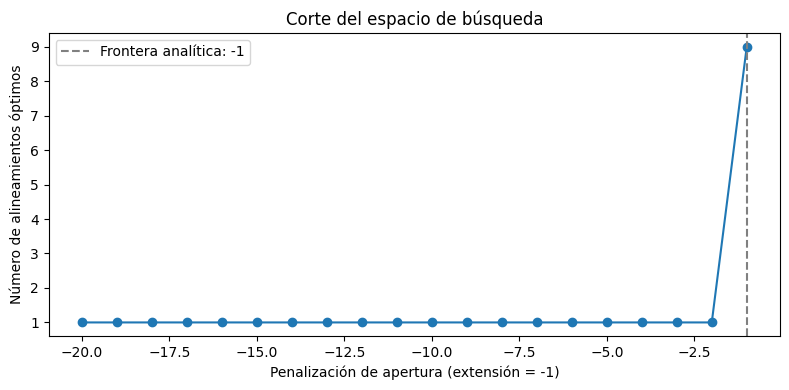

In [4]:
seccion = df_grid[df_grid['extend_gap'].eq(-1.0)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seccion['open_gap'], seccion['n_optimos'], marker='o')
ax.axvline(-1, linestyle='--', color='gray', label='Frontera analítica: -1')
ax.set_xlabel('Penalización de apertura (extensión = -1)')
ax.set_ylabel('Número de alineamientos óptimos')
ax.set_title('Corte del espacio de búsqueda')
ax.legend()
plt.tight_layout()
plt.show()

## Ejercicio 2 · Comparación «todos contra todos» de proteínas

Se prepara un archivo FASTA con cinco variantes de **una misma proteína de ejemplo**, se lee con `Bio.SeqIO` y se calculan los 25 valores de una matriz simétrica de puntuaciones. Se utiliza alineamiento **global** y la matriz **BLOSUM62**, que puntúa coincidencias y sustituciones de aminoácidos según su propensión evolutiva.

**Limitación de los datos:** el FASTA de demostración está construido de forma sintética para que el cuaderno sea autónomo. Los nombres de las variantes no representan especies reales ni permiten extraer conclusiones filogenéticas.

In [5]:
# Secuencia proteica de ejemplo y cinco variantes sintéticas reproducibles.
proteina_base = "MVLSPADKTNVKAAWGKVGAHAGEYGAEALERMFLSFPTTKTYFPHFDLSHGSAQVKGHGKKVADALTNAVAHVDDMPNALSALSDLHAHKLRVDPVNFKLLSHCLLVTLAAHLPAEFTPAVHASLDKFLASVSTVLTSKYR"
variantes = {
    'Variante_1': {},
    'Variante_2': {8: 'S'},
    'Variante_3': {8: 'S', 18: 'S', 65: 'G'},
    'Variante_4': {8: 'S', 18: 'S', 65: 'G', 90: 'V', 110: 'G', 120: 'A'},
    'Variante_5': {8: 'S', 18: 'S', 65: 'G', 90: 'V', 110: 'G', 120: 'A', 25: 'D', 45: 'E', 80: 'I'}
}

def mutar_secuencia(original, cambios):
    letras = list(original)
    for posicion, aminoacido in cambios.items():
        letras[posicion] = aminoacido
    return ''.join(letras)

fasta_path = Path('proteinas_practica2_sinteticas.fasta')
with fasta_path.open('w', encoding='utf-8') as archivo:
    for nombre, cambios in variantes.items():
        archivo.write(f'>{nombre} proteina_ejemplo_sintetica\n')
        seq = mutar_secuencia(proteina_base, cambios)
        archivo.write(f'{seq}\n')

registros = list(SeqIO.parse(fasta_path, 'fasta'))
nombres = [r.id for r in registros]
print('Secuencias cargadas:', len(registros))
for r in registros:
    print(r.id, '| longitud:', len(r.seq))

Secuencias cargadas: 5
Variante_1 | longitud: 142
Variante_2 | longitud: 142
Variante_3 | longitud: 142
Variante_4 | longitud: 142
Variante_5 | longitud: 142


### Matriz de puntuaciones usando BLOSUM62

Se calcula la puntuación de cada par, incluida la comparación de cada secuencia consigo misma. Se fijan las mismas penalizaciones de huecos para todas las comparaciones (`-10` para apertura y `-0.5` para extensión), como en los apuntes.

In [6]:
def matriz_puntuaciones(registros, nombre_matriz):
    a = Align.PairwiseAligner()
    a.mode = 'global'
    a.substitution_matrix = substitution_matrices.load(nombre_matriz)
    a.open_gap_score = -10
    a.extend_gap_score = -0.5
    nombres = [r.id for r in registros]
    valores = np.zeros((len(registros), len(registros)))
    for i, registro_i in enumerate(registros):
        for j, registro_j in enumerate(registros):
            valores[i, j] = a.score(registro_i.seq, registro_j.seq)
    return pd.DataFrame(valores, index=nombres, columns=nombres)

matriz_blosum62 = matriz_puntuaciones(registros, 'BLOSUM62')
print('Matriz BLOSUM62 (5 × 5 = 25 puntuaciones)')
display(matriz_blosum62)
assert matriz_blosum62.shape == (5, 5)
assert np.allclose(matriz_blosum62.values, matriz_blosum62.values.T)

Matriz BLOSUM62 (5 × 5 = 25 puntuaciones)


,Variante_1,Variante_2,Variante_3,Variante_4,Variante_5
Variante_1,733.0,729.0,719.0,708.0,691.0
Variante_2,729.0,732.0,722.0,711.0,694.0
Variante_3,719.0,722.0,732.0,721.0,704.0
Variante_4,708.0,711.0,721.0,733.0,716.0
Variante_5,691.0,694.0,704.0,716.0,730.0


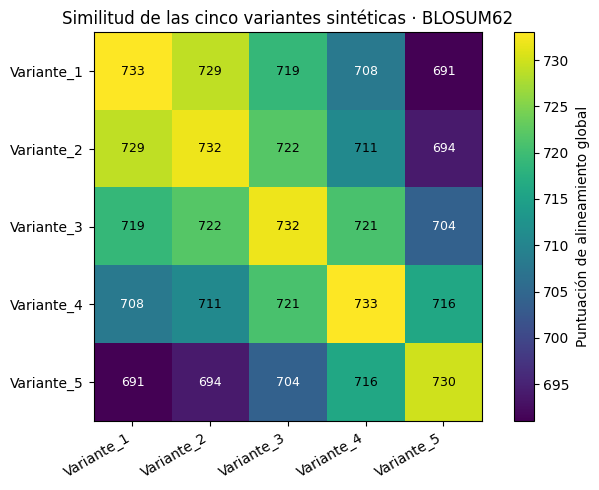

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(matriz_blosum62.values, cmap='viridis')
ax.set_xticks(range(5), nombres, rotation=30, ha='right')
ax.set_yticks(range(5), nombres)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{matriz_blosum62.iloc[i, j]:.0f}', ha='center', va='center',
                color='white' if im.norm(matriz_blosum62.iloc[i,j]) < 0.45 else 'black', fontsize=9)
fig.colorbar(im, ax=ax, label='Puntuación de alineamiento global')
ax.set_title('Similitud de las cinco variantes sintéticas · BLOSUM62')
plt.tight_layout()
plt.show()

### Comparación con otras matrices de sustitución

Se repite el cálculo con **BLOSUM45** y **PAM250** para comprobar que cambiar la matriz modifica las puntuaciones. No se comparan directamente valores absolutos entre matrices como si fueran una medida idéntica, ya que cada una tiene una escala de puntuación propia.

,Matriz,Media puntuaciones entre variantes,Mínimo,Máximo
0,BLOSUM62,711.5,691.0,729.0
1,BLOSUM45,847.3,824.0,869.0
2,PAM250,646.8,633.0,659.0


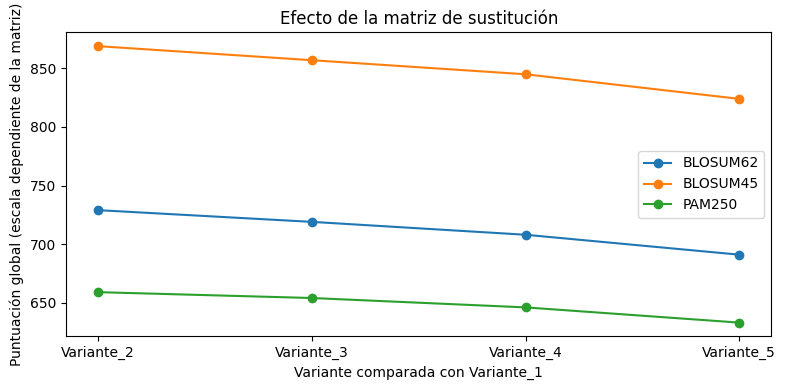

In [8]:
matrices = {'BLOSUM62': matriz_blosum62,
            'BLOSUM45': matriz_puntuaciones(registros, 'BLOSUM45'),
            'PAM250': matriz_puntuaciones(registros, 'PAM250')}

resumen = []
for nombre, df in matrices.items():
    fuera_diagonal = df.values[np.triu_indices(len(df), k=1)]
    resumen.append({'Matriz': nombre, 'Media puntuaciones entre variantes': fuera_diagonal.mean(),
                    'Mínimo': fuera_diagonal.min(), 'Máximo': fuera_diagonal.max()})
display(pd.DataFrame(resumen).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for nombre, df in matrices.items():
    ax.plot(range(1, 5), [df.iloc[0, j] for j in range(1, 5)], marker='o', label=nombre)
ax.set_xticks(range(1, 5), nombres[1:])
ax.set_xlabel('Variante comparada con Variante_1')
ax.set_ylabel('Puntuación global (escala dependiente de la matriz)')
ax.set_title('Efecto de la matriz de sustitución')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** En el conjunto sintético, las variantes más próximas a la secuencia inicial presentan mayor similitud según las mutaciones introducidas. La diagonal compara cada secuencia consigo misma y, por ello, suele mostrar puntuaciones altas. El mapa de calor es simétrico porque el esquema empleado puntúa igual un par de secuencias con independencia del orden. BLOSUM62, BLOSUM45 y PAM250 producen escalas distintas; para sacar conclusiones sobre evolución entre especies sería necesario sustituir este FASTA por **secuencias auténticas de la misma proteína obtenidas de una base de datos**, y justificar su procedencia.

**Aportación adicional.** Se comprueba automáticamente que la matriz es simétrica y que contiene exactamente 25 puntuaciones.

## Ejercicio 3 · Escalabilidad de los alineamientos

Se generan pares de secuencias de ADN de longitudes **100, 500, 1000, 2000 y 5000** bases, utilizando `random` con una semilla fija. Para medir el tiempo de cálculo del alineamiento se usa `time.perf_counter`, de alta resolución. Se emplea `.score()` porque el objetivo es medir el coste de obtener la puntuación óptima **sin enumerar todas las soluciones posibles**. Se repite cada medición tres veces y se usa la mediana para reducir el ruido.

In [9]:
random.seed(42)
longitudes = [100, 500, 1000, 2000, 5000]

def adn_aleatorio(longitud):
    return ''.join(random.choices('ACGT', k=longitud))

alineador_tiempo = Align.PairwiseAligner()
alineador_tiempo.mode = 'global'
alineador_tiempo.match_score = 1
alineador_tiempo.mismatch_score = -1
alineador_tiempo.open_gap_score = -2
alineador_tiempo.extend_gap_score = -0.5

tiempos = []
for longitud in longitudes:
    a, b = adn_aleatorio(longitud), adn_aleatorio(longitud)
    duraciones = []
    for repeticion in range(3):
        inicio = perf_counter()
        puntuacion = alineador_tiempo.score(a, b)
        duraciones.append((perf_counter() - inicio) * 1000)
    tiempos.append({'longitud': longitud, 'tiempo_mediano_ms': np.median(duraciones),
                    'tiempo_min_ms': np.min(duraciones), 'tiempo_max_ms': np.max(duraciones),
                    'score': puntuacion})

df_tiempos = pd.DataFrame(tiempos)
display(df_tiempos.round(3))

,longitud,tiempo_mediano_ms,tiempo_min_ms,tiempo_max_ms,score
0,100,0.045,0.042,0.082,-5.5
1,500,1.010,0.985,1.013,-6.0
2,1000,4.468,4.465,4.769,-8.5
3,2000,16.778,16.592,17.641,5.0
4,5000,107.374,106.030,108.632,-5.0


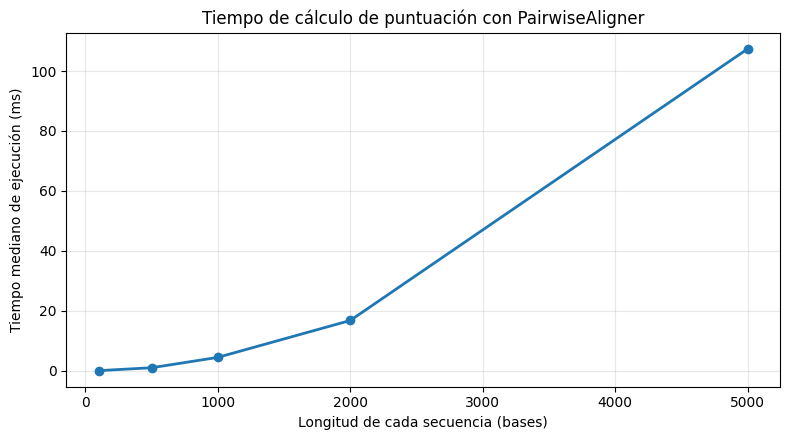

Relación de tiempo 5000 / 100 bases: 2411.98


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_tiempos['longitud'], df_tiempos['tiempo_mediano_ms'], marker='o', linewidth=2)
ax.set_xlabel('Longitud de cada secuencia (bases)')
ax.set_ylabel('Tiempo mediano de ejecución (ms)')
ax.set_title('Tiempo de cálculo de puntuación con PairwiseAligner')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Relación de tiempo 5000 / 100 bases:',
      round(df_tiempos.iloc[-1]['tiempo_mediano_ms'] / df_tiempos.iloc[0]['tiempo_mediano_ms'], 2))

**Interpretación.** Al aumentar la longitud, aumenta generalmente el tiempo necesario para calcular el alineamiento. En programación dinámica, una matriz para dos secuencias de longitudes $N$ y $M$ tiene tamaño proporcional a $N\times M$; para dos secuencias igual de largas, el coste teórico general de calcular el alineamiento por este procedimiento es de orden **$O(N^2)$**. Los tiempos concretos pueden variar según el ordenador, la implementación y las secuencias. La gráfica mide la operación `.score()`, no el tiempo adicional de generar o mostrar todos los alineamientos.

**Aportación adicional.** Se usa una semilla reproducible y una mediana de tres medidas por longitud, en lugar de una única observación susceptible al ruido del sistema.

## Conclusiones generales

1. Los parámetros de apertura y extensión de huecos influyen tanto en la puntuación como en el número de alineamientos óptimos. La frontera de empate depende del esquema de puntuación, no solo de las secuencias.
2. La comparación de proteínas mediante BLOSUM62 produce una matriz que resume la similitud calculada para cada pareja. El resultado también depende de la matriz de sustitución y de las penalizaciones por huecos.
3. El análisis de tiempos muestra por qué la escalabilidad es relevante: al aumentar las longitudes de las secuencias, el coste de un alineamiento exacto tiende a crecer de forma importante.

**Referencia docente:** *T03 · Bioinformática en laboratorio · Sesión 03: Alineamientos* y *Práctica 2*, material proporcionado para la asignatura.